In [19]:
# conda env 'at3d'

import pymap3d as pm
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import at3d
import netCDF4 as nc
import os
from scipy.interpolate import griddata

In [20]:
## INPUT
# RT Grid
rte_grid_file = '../intermediate_data/RTG_default.nc'
# CTH
cth_file = '../intermediate_data/MISR_CTH_CAMP2Ex_RF17_Pris2.nc'
# Carved Volume
carved_vol_file = '../intermediate_data/CARVED_VOL_cloudy.nc'
# LCL
lcl = 0.4

## OUTPUT
out_file = '../intermediate_data/CVM_prist2.nc'

In [21]:
rte_grid = xr.load_dataset(rte_grid_file)
cloud_data = xr.load_dataset(cth_file)
carved_volume = xr.load_dataset(carved_vol_file)

In [22]:
wgs84 = pm.Ellipsoid('wgs84')
e, n, u = pm.geodetic2enu(
    cloud_data.lat1100.data,
    cloud_data.lon1100.data,
    cloud_data.cth.data,
    cloud_data.center_lat.data,
    cloud_data.center_lon.data,
    0.0,
    ell=wgs84,
    deg=True
)
cloud_data['E'] = (['y1100', 'x1100'], e/1000)
cloud_data['N'] = (['y1100', 'x1100'], n/1000)
cloud_data['z_cloud'] = (['y1100', 'x1100'], u/1000)

# Horizontal shift to place origin at the corner of the rte grid (maintain centering)
cloud_data['E'] = cloud_data.E + np.max(rte_grid.x.data)/2
cloud_data['E'] = cloud_data.E.assign_attrs(units='km')
cloud_data['N'] = cloud_data.N + np.max(rte_grid.y.data)/2
cloud_data['N'] = cloud_data.N.assign_attrs(units='km')

In [23]:
# Create the new grid
grid_x, grid_y = np.meshgrid(rte_grid.x.data, rte_grid.y.data, indexing='ij')

# Flatten the original grid and data
points = np.array([cloud_data.E.data.flatten(), cloud_data.N.data.flatten()]).T
values = cloud_data.z_cloud.data.flatten()

# Mask out NaN values
mask = ~np.isnan(values)
points = points[mask]
values = values[mask]

# Interpolate the data onto the new grid
cth_interp = griddata(points, values, (grid_x, grid_y), method='linear')

In [24]:
cth_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, cth_interp, side='right')]

In [25]:
cloud_data

<xarray.Dataset>
Dimensions:     (y1100: 48, x1100: 48)
Dimensions without coordinates: y1100, x1100
Data variables:
    cth         (y1100, x1100) float32 228.0 239.0 -70.0 ... 522.0 274.0
    cm          (y1100, x1100) float32 4.0 3.0 4.0 nan nan ... nan 2.0 3.0 4.0
    squi        (y1100, x1100) float32 61.0 41.0 63.0 nan ... nan 37.0 38.0 84.0
    lat1100     (y1100, x1100) float64 18.99 18.99 18.99 ... 18.48 18.48 18.48
    lon1100     (y1100, x1100) float64 120.1 120.1 120.1 ... 120.5 120.6 120.6
    center_lat  float64 18.74
    center_lon  float64 120.3
    E           (y1100, x1100) float64 -14.68 -13.59 -12.49 ... 31.19 32.28
    N           (y1100, x1100) float64 36.82 36.72 36.62 ... -19.12 -19.22
    z_cloud     (y1100, x1100) float64 0.1229 0.1383 -0.1666 ... 0.4213 0.1689
Attributes:
    orbit:    105254
    path:     117
    blocks:   [75 76]

Text(0.5, 1.0, 'CTH on RTE Grid')

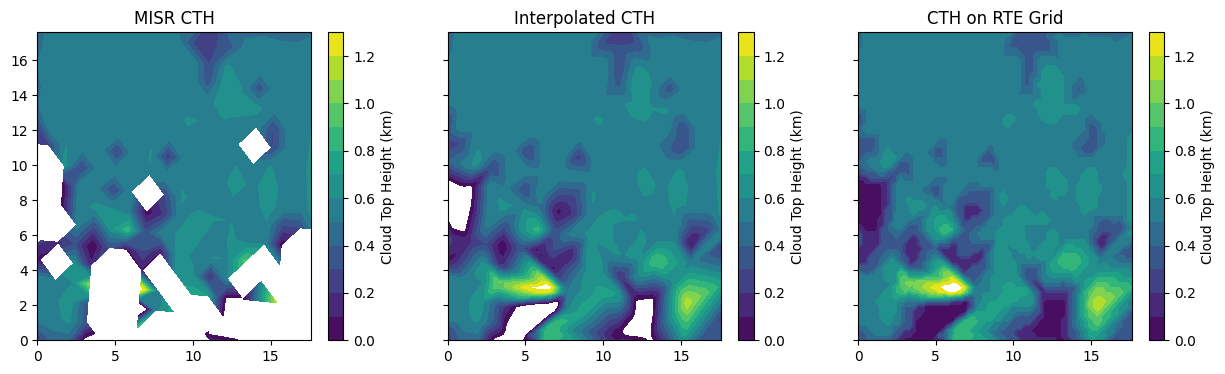

In [26]:
levels = np.arange(0, 1.4, 0.1)
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
c0 = ax[0].contourf(cloud_data.E.data, cloud_data.N.data, cloud_data.z_cloud.data, levels=levels)
plt.colorbar(c0, ax=ax[0], label='Cloud Top Height (km)')
ax[0].set_title('MISR CTH')
c1 = ax[1].contourf(grid_x, grid_y, cth_interp, levels=levels)
plt.colorbar(c1, ax=ax[1], label='Cloud Top Height (km)')
ax[1].set_title('Interpolated CTH')
c2 = ax[2].contourf(grid_x, grid_y, cth_on_rte_grid, levels=levels)
plt.colorbar(c2, ax=ax[2], label='Cloud Top Height (km)')
ax[2].set_title('CTH on RTE Grid')

In [27]:
cth_on_rte_grid = np.expand_dims(cth_on_rte_grid, axis=-1)
cth_mask = (rte_grid.z.data <= cth_on_rte_grid).astype(int)
rte_grid['cth_mask'] = (['x', 'y', 'z'], cth_mask)

In [28]:
lcl_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, lcl, side='right') - 1]
lcl_mask = np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z']))
lcl_mask[:,:,rte_grid.z.data >= lcl_on_rte_grid] = 1
rte_grid['lcl_mask'] = (['x', 'y', 'z'], lcl_mask)

In [29]:
rte_grid['carved_mask'] = (['x', 'y', 'z'], carved_volume.mask.data)

In [30]:
rbg_mask = np.zeros((rte_grid.dims['y'], rte_grid.dims['x'], rte_grid.dims['z'], 3))
rbg_mask[:,:,:,0] = rte_grid.cth_mask # Red
rbg_mask[:,:,:,1] = rte_grid.lcl_mask # Green
rbg_mask[:,:,:,2] = rte_grid.carved_mask # Blue
rte_grid['rbg_mask'] = (['x', 'y', 'z', 'rgb'], rbg_mask)

In [31]:
mask = np.logical_and(rte_grid.cth_mask.data, rte_grid.lcl_mask.data)
mask = np.logical_and(rte_grid.carved_mask.data, mask)
mask[0,:,:] = mask[-1,:,:] = mask[:,0,:] = mask[:,-1,:] = 0.0
rte_grid['cloud_volume_mask'] = (['x', 'y', 'z'], mask)
rte_grid.to_netcdf(out_file)

In [32]:
print('Number of free parameters: {}'.format(np.sum(rte_grid.cloud_volume_mask.data)))

Number of free parameters: 10216


In [33]:
rte_grid['cfba'] = rte_grid.cloud_volume_mask.sum(('x','y')) / (rte_grid.dims['x'] * rte_grid.dims['y'])

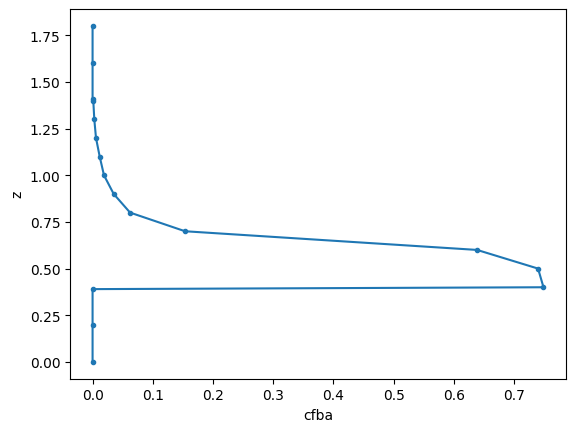

In [35]:
rte_grid.cfba.plot(y='z', marker='.')

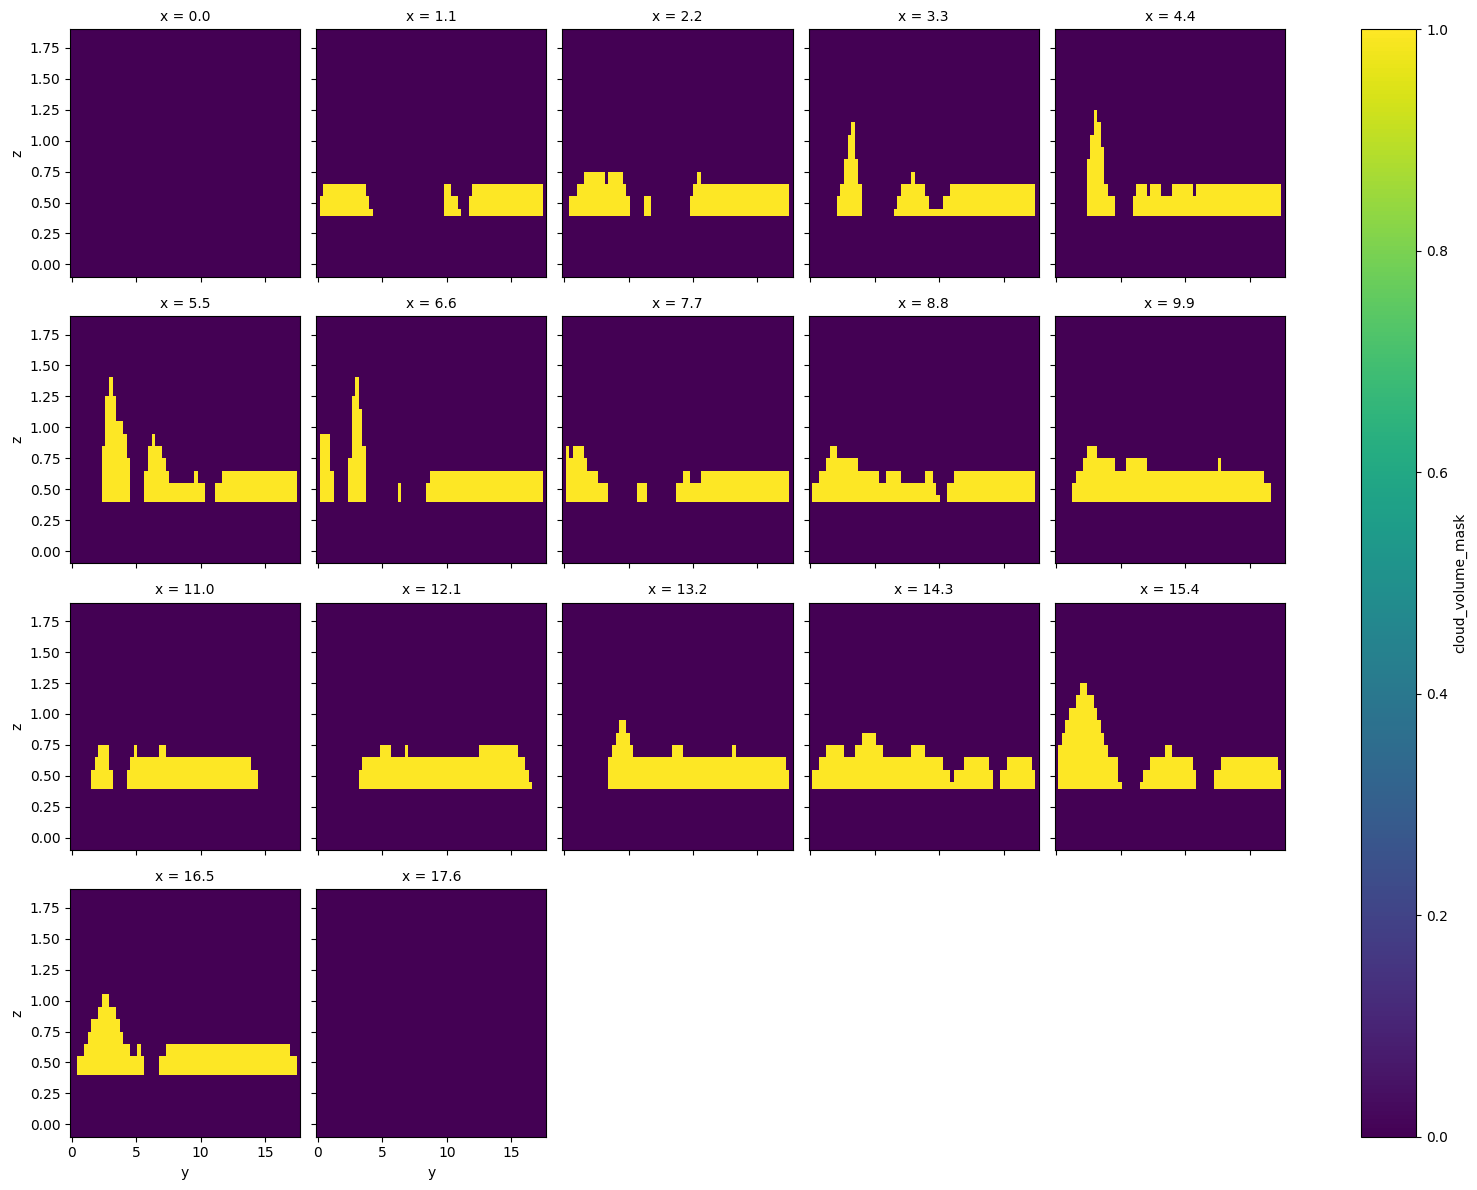

In [36]:
rte_grid.cloud_volume_mask.isel(x=slice(0,None,4)).plot(x='y', y='z', col='x', col_wrap=5)

In [ ]:
rte_grid.rbg_mask.isel(x=slice(0,None,4)).plot.imshow(x='y', y='z', col='x', col_wrap=5)